In [1]:
# git clone https://github.com/boomb0om/CRAFT-text-detection
# cd CRAFT-text-detection/
# pip install -r requirements.txt

# pip install huggingface_hub==0.25.2

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import os
import sys
import warnings
from PIL import Image
from time import time

craft_path = os.path.abspath("CRAFT-text-detection")
if craft_path not in sys.path:
    sys.path.insert(0, craft_path)

from CRAFT import CRAFTModel, draw_polygons, preprocess_image

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    craft = CRAFTModel(
        cache_dir="weights/",
        device="cpu",
        use_refiner=True,
        fp16=False,
        canvas_size=1280,
        mag_ratio=1.5,
        text_threshold=0.7,
        link_threshold=0.4,
        low_text=0.4,
    )

In [ ]:
def test_on_image(image_path, model):
    image = Image.open(image_path).convert("RGB")

    print(f"Изображение: {image_path}")
    plt.imshow(image)
    plt.axis("off")
    plt.show()

    start_time = time()
    image_array = np.array(image)
    image_tensor, ratio_w, ratio_h = preprocess_image(
        image_array,
        canvas_size=model.canvas_size,
        mag_ratio=model.mag_ratio,
    )
    text_score_map, link_score_map = model.get_text_map(image_tensor, ratio_w, ratio_h)
    end_time = time()
    elapsed_time = f"{end_time - start_time:.3f}"

    print(f"Изображение с обнаруженным текстом (время: {elapsed_time} секунд):")
    plt.imshow(draw_polygons(image, model.get_polygons(image)))
    plt.axis("off")
    plt.show()

    print("Тепловая карта символов (region score):")
    plt.imshow(text_score_map, cmap="jet")
    plt.axis("off")
    plt.show()

    print("Тепловая карта связей (affinity score):")
    plt.imshow(link_score_map, cmap="jet")
    plt.axis("off")
    plt.show()

In [4]:
IMAGE_PATH_1 = "1.png"
IMAGE_PATH_2 = "2.png"
IMAGE_PATH_3 = "3.png"
IMAGE_PATH_4 = "4.png"
IMAGE_PATH_5 = "5.png"
IMAGE_PATH_6 = "6.png"
IMAGE_PATH_7 = "7.png"
IMAGE_PATH_8 = "8.png"
IMAGE_PATH_9 = "9.png"
IMAGE_PATH_10 = "10.png"

Изображение: 1.png


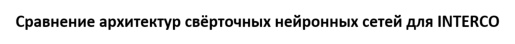

Изображение с обнаруженным текстом (время: 0.611 секунд):


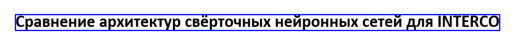

Тепловая карта символов (region score):


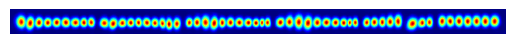

Тепловая карта связей (affinity score):


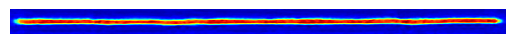

In [5]:
test_on_image("1.png", model=craft)

Изображение: 2.png


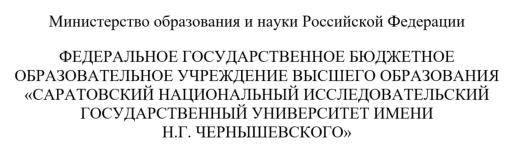

Изображение с обнаруженным текстом (время: 2.673 секунд):


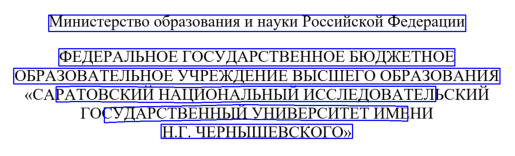

Тепловая карта символов (region score):


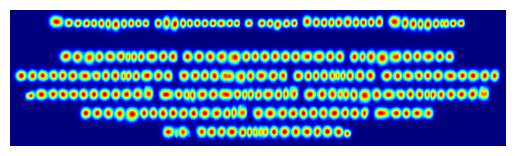

Тепловая карта связей (affinity score):


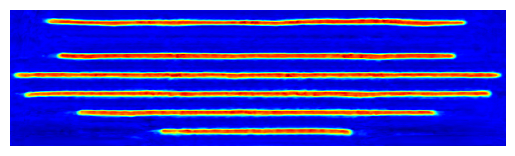

In [6]:
test_on_image("2.png", model=craft)

Изображение: 3.png


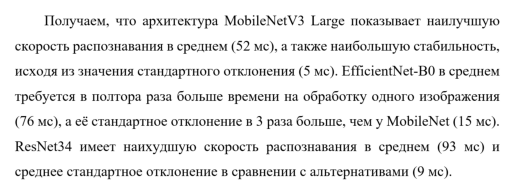

Изображение с обнаруженным текстом (время: 3.804 секунд):


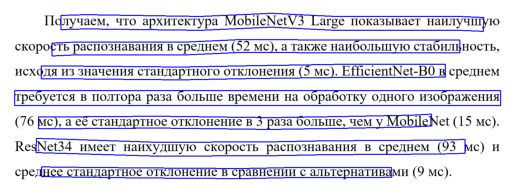

Тепловая карта символов (region score):


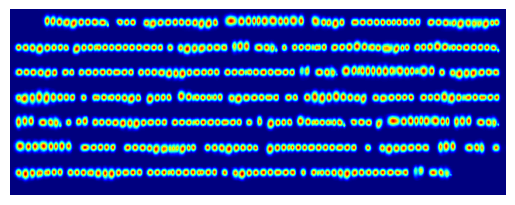

Тепловая карта связей (affinity score):


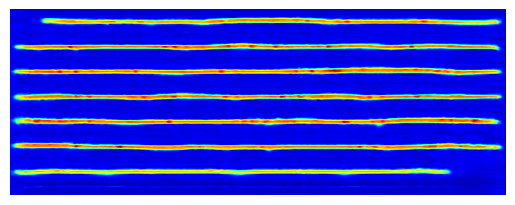

In [7]:
test_on_image("3.png", model=craft)

Изображение: 4.png


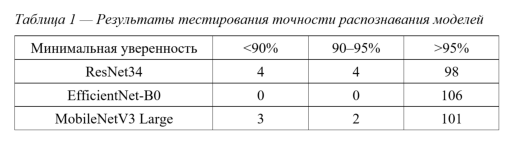

Изображение с обнаруженным текстом (время: 2.761 секунд):


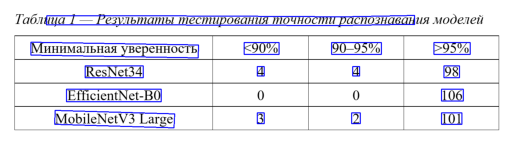

Тепловая карта символов (region score):


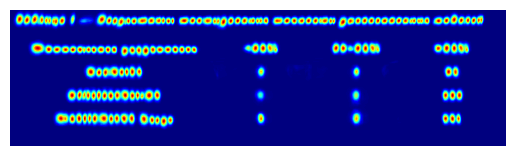

Тепловая карта связей (affinity score):


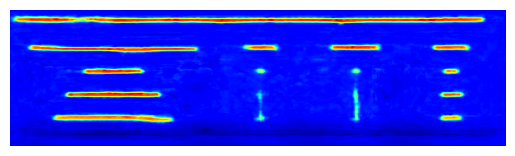

In [8]:
test_on_image("4.png", model=craft)

Изображение: 5.png


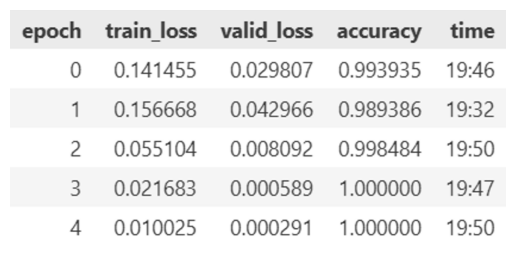

Изображение с обнаруженным текстом (время: 5.592 секунд):


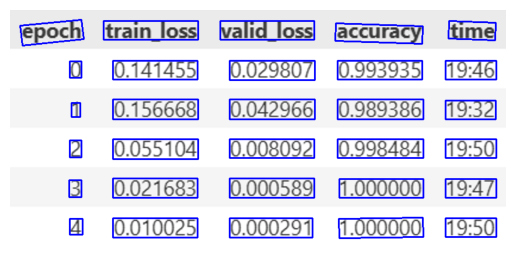

Тепловая карта символов (region score):


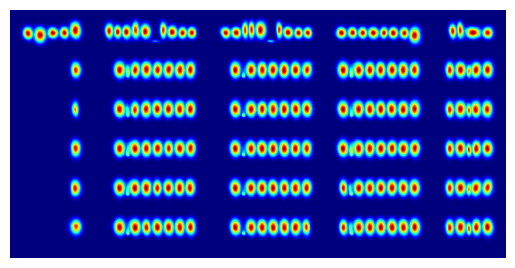

Тепловая карта связей (affinity score):


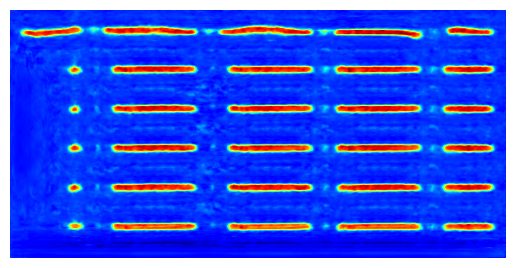

In [9]:
test_on_image("5.png", model=craft)

Изображение: 6.png


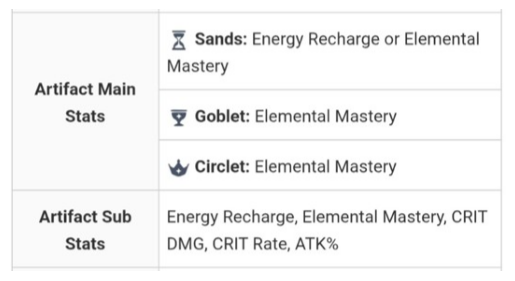

Изображение с обнаруженным текстом (время: 2.475 секунд):


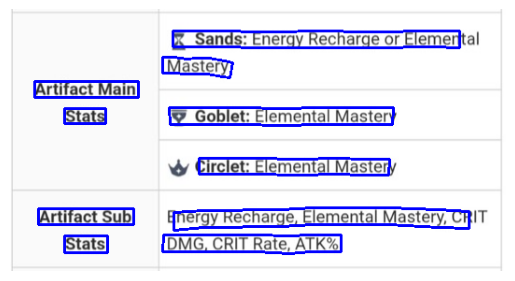

Тепловая карта символов (region score):


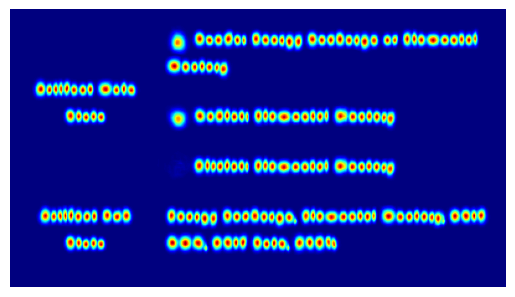

Тепловая карта связей (affinity score):


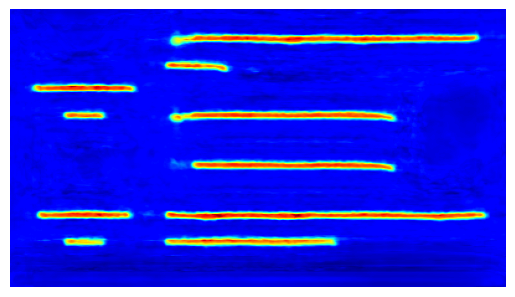

In [10]:
test_on_image("6.png", model=craft)

Изображение: 7.png


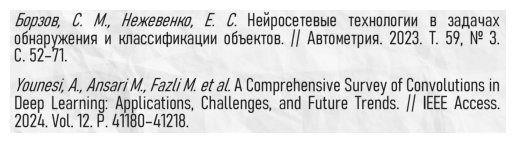

Изображение с обнаруженным текстом (время: 2.693 секунд):


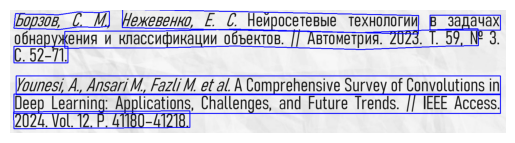

Тепловая карта символов (region score):


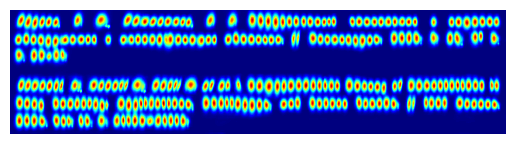

Тепловая карта связей (affinity score):


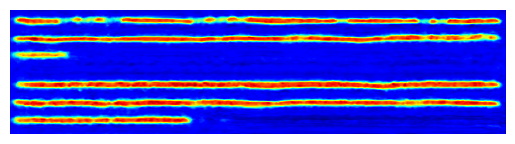

In [11]:
test_on_image("7.png", model=craft)

Изображение: 8.png


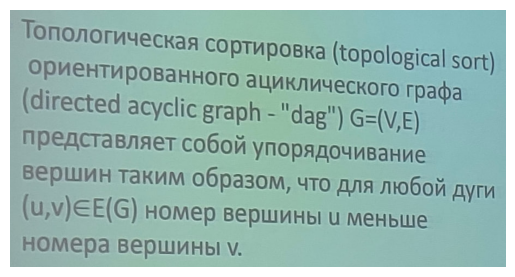

Изображение с обнаруженным текстом (время: 5.162 секунд):


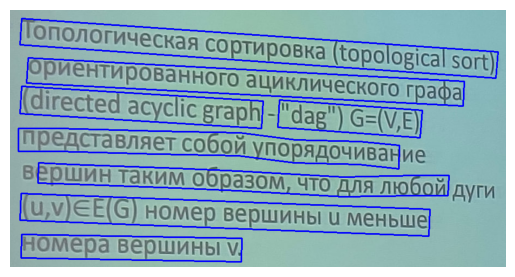

Тепловая карта символов (region score):


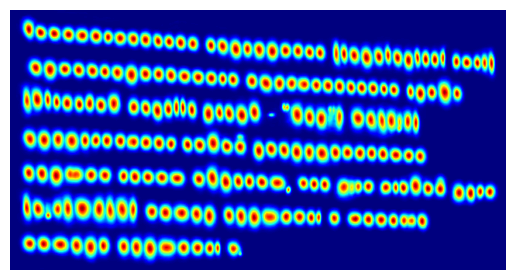

Тепловая карта связей (affinity score):


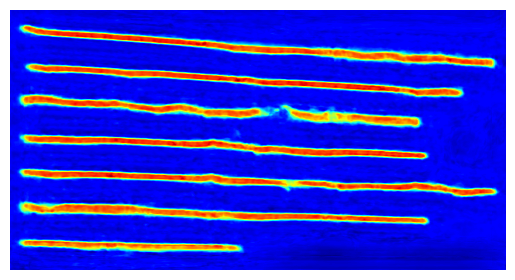

In [12]:
test_on_image("8.png", model=craft)

Изображение: 9.png


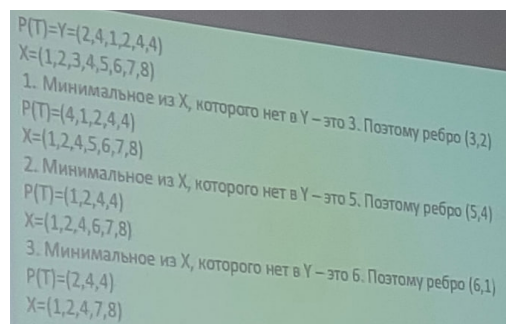

Изображение с обнаруженным текстом (время: 4.220 секунд):


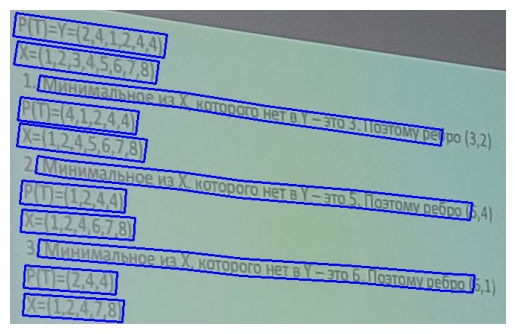

Тепловая карта символов (region score):


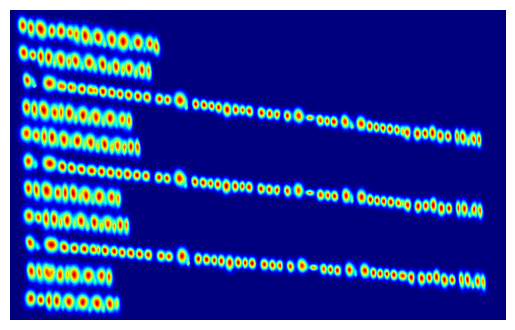

Тепловая карта связей (affinity score):


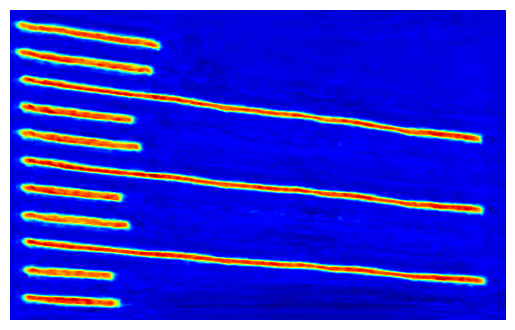

In [13]:
test_on_image("9.png", model=craft)

Изображение: 10.png


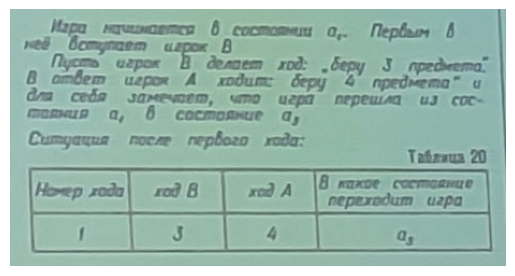

Изображение с обнаруженным текстом (время: 1.682 секунд):


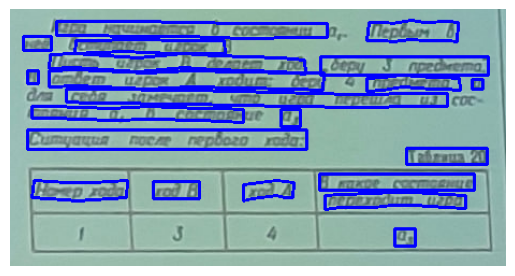

Тепловая карта символов (region score):


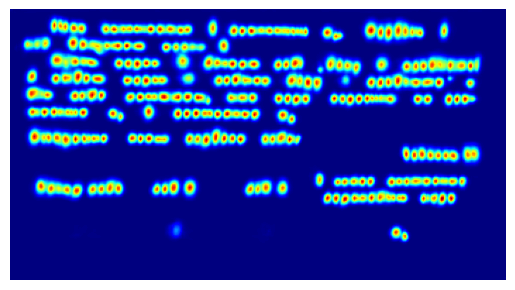

Тепловая карта связей (affinity score):


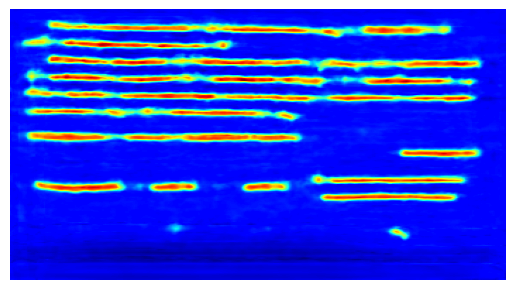

In [14]:
test_on_image("10.png", model=craft)

In [ ]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    craft_tuned = CRAFTModel(
        cache_dir="weights/",
        device="cpu",
        use_refiner=True,
        fp16=False,
        canvas_size=1280,
        mag_ratio=1.5,
        text_threshold=0.4,
        link_threshold=0.4,
        low_text=0.2,
    )

Изображение: 1.png


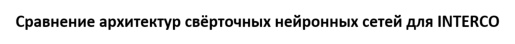

Изображение с обнаруженным текстом (время: 0.602 секунд):


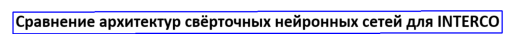

Тепловая карта символов (region score):


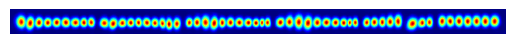

Тепловая карта связей (affinity score):


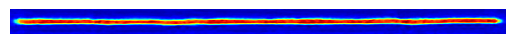

In [16]:
test_on_image(IMAGE_PATH_1, model=craft_tuned)

Изображение: 2.png


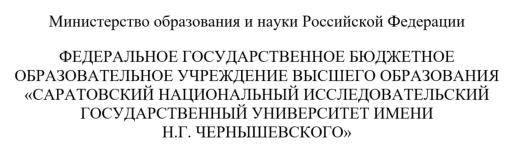

Изображение с обнаруженным текстом (время: 2.827 секунд):


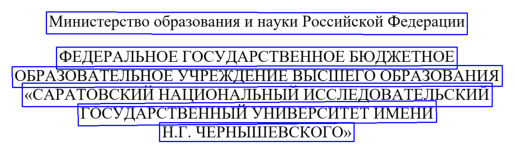

Тепловая карта символов (region score):


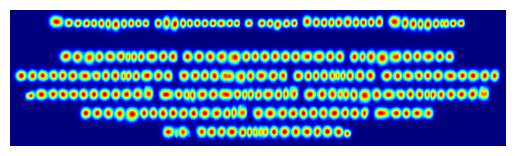

Тепловая карта связей (affinity score):


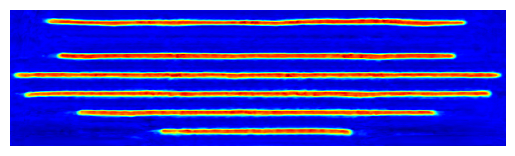

In [17]:
test_on_image(IMAGE_PATH_2, model=craft_tuned)

Изображение: 3.png


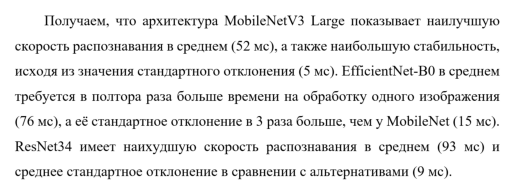

Изображение с обнаруженным текстом (время: 3.764 секунд):


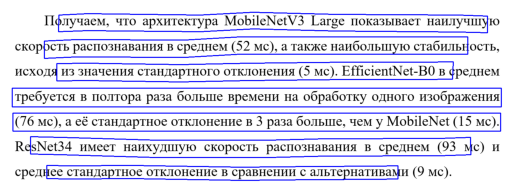

Тепловая карта символов (region score):


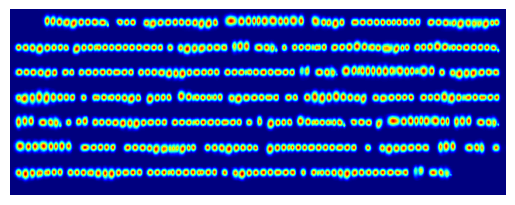

Тепловая карта связей (affinity score):


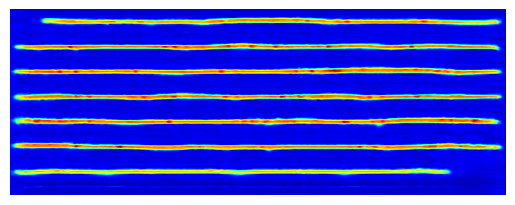

In [18]:
test_on_image(IMAGE_PATH_3, model=craft_tuned)

Изображение: 4.png


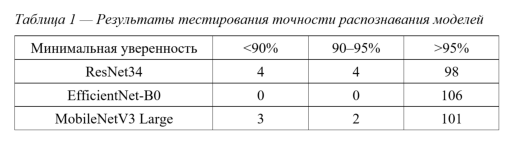

Изображение с обнаруженным текстом (время: 2.758 секунд):


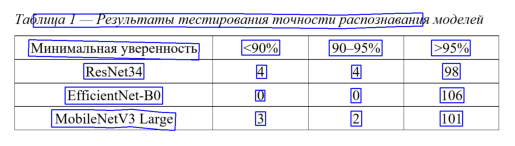

Тепловая карта символов (region score):


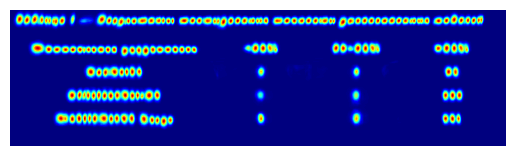

Тепловая карта связей (affinity score):


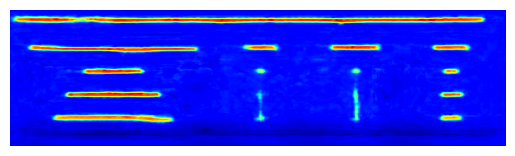

In [19]:
test_on_image(IMAGE_PATH_4, model=craft_tuned)

Изображение: 5.png


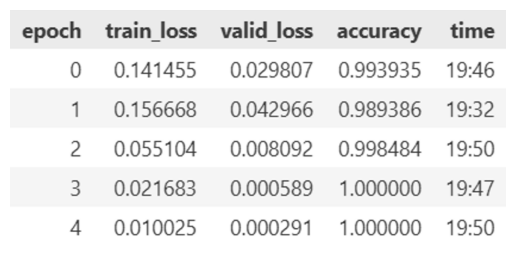

Изображение с обнаруженным текстом (время: 4.961 секунд):


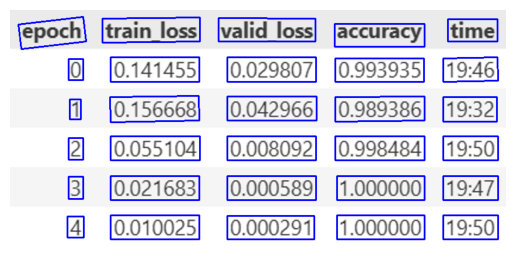

Тепловая карта символов (region score):


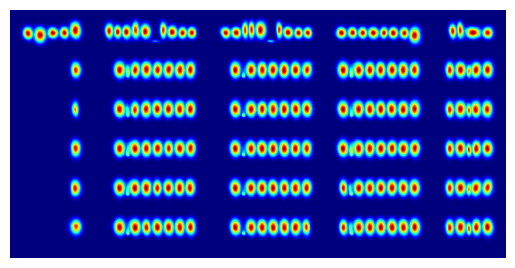

Тепловая карта связей (affinity score):


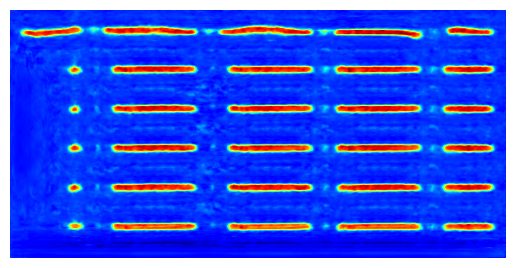

In [20]:
test_on_image(IMAGE_PATH_5, model=craft_tuned)

Изображение: 6.png

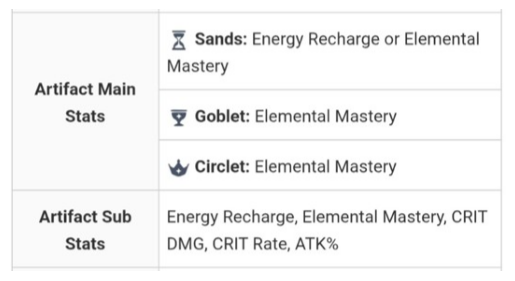

Изображение с обнаруженным текстом (время: 2.271 секунд):


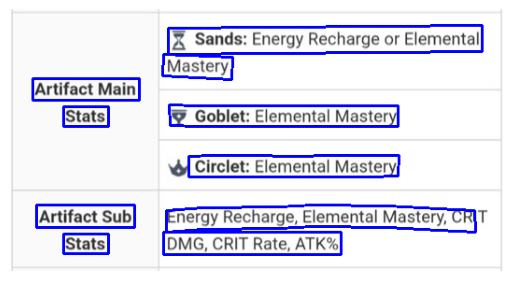

Тепловая карта символов (region score):


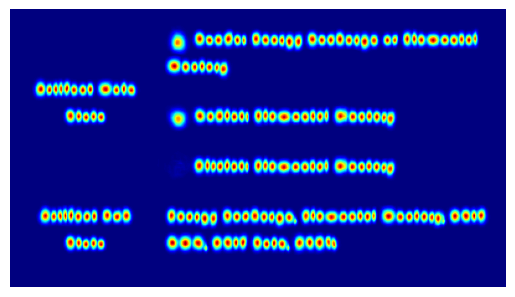

Тепловая карта связей (affinity score):


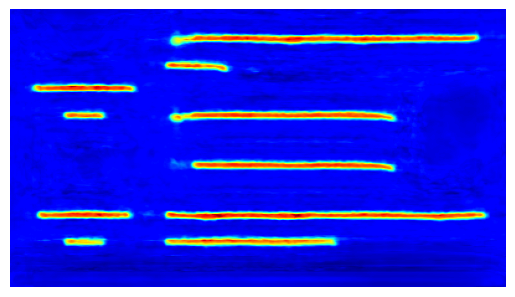

In [21]:
test_on_image(IMAGE_PATH_6, model=craft_tuned)

Изображение: 7.png


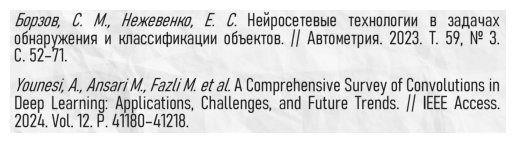

Изображение с обнаруженным текстом (время: 2.600 секунд):


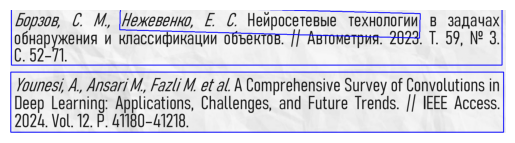

Тепловая карта символов (region score):


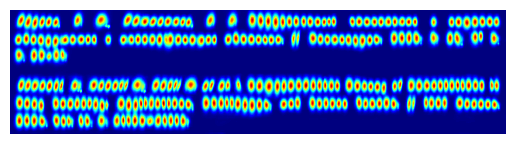

Тепловая карта связей (affinity score):


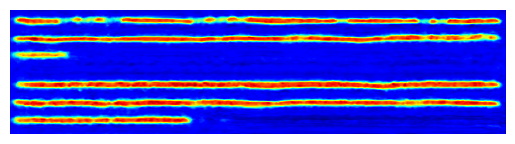

In [22]:
test_on_image(IMAGE_PATH_7, model=craft_tuned)

Изображение: 8.png


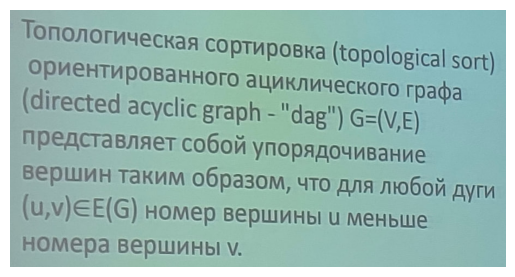

Изображение с обнаруженным текстом (время: 5.153 секунд):


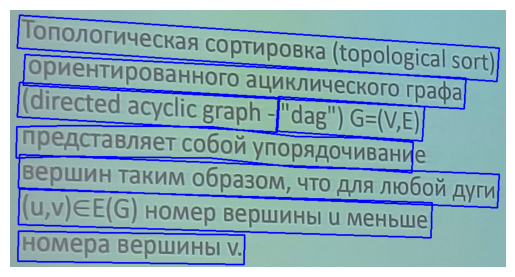

Тепловая карта символов (region score):


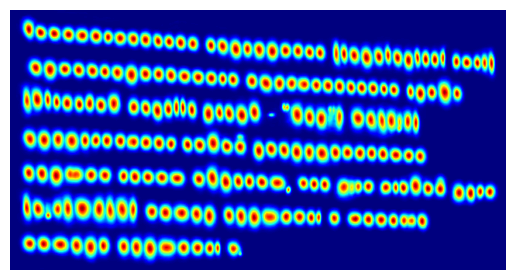

Тепловая карта связей (affinity score):


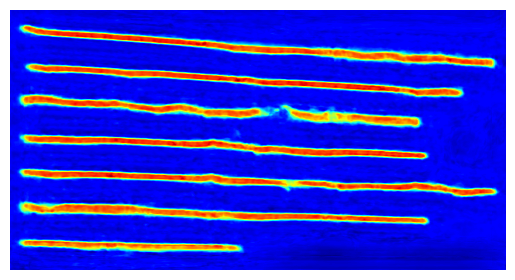

In [23]:
test_on_image(IMAGE_PATH_8, model=craft_tuned)

Изображение: 9.png


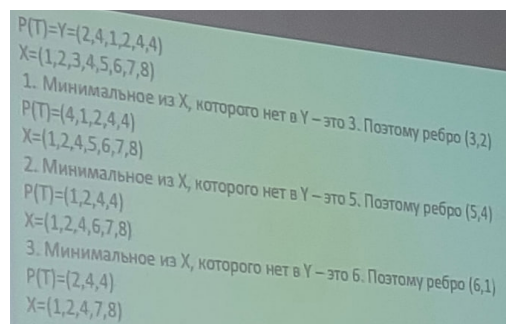

Изображение с обнаруженным текстом (время: 4.099 секунд):


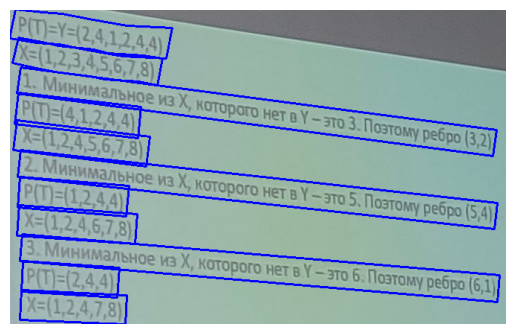

Тепловая карта символов (region score):


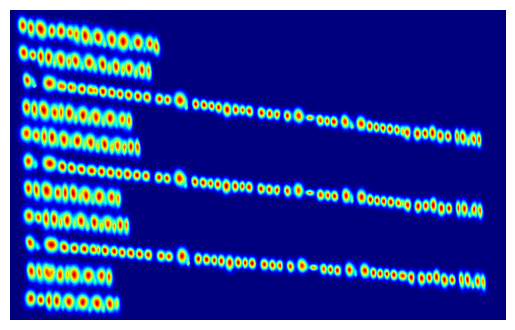

Тепловая карта связей (affinity score):


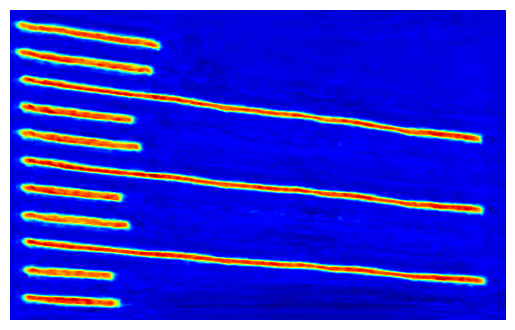

In [24]:
test_on_image(IMAGE_PATH_9, model=craft_tuned)

Изображение: 10.png


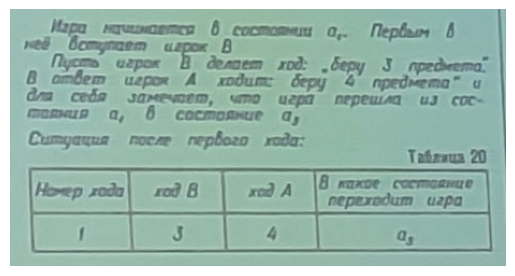

Изображение с обнаруженным текстом (время: 1.731 секунд):


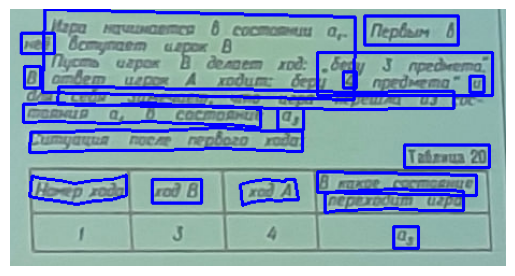

Тепловая карта символов (region score):


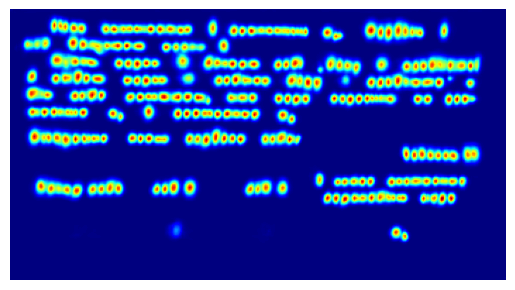

Тепловая карта связей (affinity score):


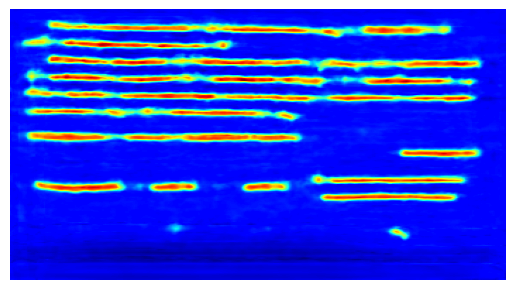

In [25]:
test_on_image(IMAGE_PATH_10, model=craft_tuned)